# Benchmark Diversity & Comprehensiveness Analysis

This notebook computes **Diversity** (semantic, structural, complexity spread) and **Comprehensiveness** (class / property / feature coverage) metrics for two NL2SPARQL benchmarks, and generates three publication-ready figures.

In [1]:
import os, json, yaml

# Prevent tokenizers / OpenMP from crashing the kernel on macOS
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

from sentence_transformers import SentenceTransformer

from metrics import measure_diversity, measure_comprehensiveness, measure_redundancy
from plots import plot_semantic_embeddings, plot_structural_diversity, plot_comprehensiveness_radar, plot_redundancy, plot_coverage_table

os.makedirs("figures", exist_ok=True)

sbert = SentenceTransformer("BAAI/bge-large-en-v1.5")

## 1. Load Benchmark Data
Provide the paths to the two JSONL benchmark files and the KG name (must match a directory under `kgs_data/`).

In [2]:
import random
random.seed(42)

# ---- Configuration --------------------------------------------------------
f1 = "querybloom/analyze/new_data/dblp-full.yaml"
f2 = "querybloom/analyze/new_data/dblp-test.jsonl"

label1 = "QueryBloom (Full)"
label2 = "Baseline"

kg_name = "dblp"        # directory name under kgs_data/
endpoint = "dblp"          # SPARQL endpoint alias for entity-type resolution
query_endpoint = "dblp"  # endpoint used to execute queries for result-row counts
# ---------------------------------------------------------------------------

project_root = os.path.abspath(os.path.join(os.getcwd(), "../../"))

def load_data(filepath):
    full_path = os.path.join(project_root, filepath)
    with open(full_path, "r") as f:
        records = yaml.safe_load(f) if filepath.endswith((".yaml", ".yml")) else [json.loads(line) for line in f if line.strip()]

    if not isinstance(records, list):
        raise ValueError(f"Expected a list of records in {filepath}")

    normalized = []
    for index, record in enumerate(records, start=1):
        question = record.get("question", record.get("text"))
        sparql = record.get("sparql", record.get("query"))
        if question is None or sparql is None:
            raise KeyError(f"Record {index} in {filepath} must contain question/text and sparql/query")
        normalized.append({"question": question, "sparql": sparql})
    return normalized

data1 = load_data(f1)
data2 = load_data(f2)

# Balance: downsample the larger set to match the smaller one
target_size = min(len(data1), len(data2))
if len(data1) > target_size:
    data1 = random.sample(data1, target_size)
elif len(data2) > target_size:
    data2 = random.sample(data2, target_size)

queries1  = [d["sparql"]   for d in data1 if "sparql"   in d]
queries2  = [d["sparql"]   for d in data2 if "sparql"   in d]
questions1 = [d["question"] for d in data1 if "question" in d]
questions2 = [d["question"] for d in data2 if "question" in d]

print(f"{label1}: {len(data1)} samples,  {label2}: {len(data2)} samples")


QueryBloom (Full): 85 samples,  Baseline: 85 samples


## 2. Compute Metrics

Run all diversity and comprehensiveness metrics in one pass per benchmark.

In [3]:
from tqdm.auto import tqdm

rewrite_cache=True

steps = [
    ("Diversity",        label1, lambda: measure_diversity(queries1, questions1, endpoint=endpoint, sbert_model=sbert, query_endpoint=query_endpoint, kg_name=kg_name, rewrite_cache=rewrite_cache)),
    ("Diversity",        label2, lambda: measure_diversity(queries2, questions2, endpoint=endpoint, sbert_model=sbert, query_endpoint=query_endpoint, kg_name=kg_name, rewrite_cache=rewrite_cache)),
    ("Comprehensiveness", label1, lambda: measure_comprehensiveness(queries1, kg_name, endpoint=endpoint, rewrite_cache=rewrite_cache)),
    ("Comprehensiveness", label2, lambda: measure_comprehensiveness(queries2, kg_name, endpoint=endpoint, rewrite_cache=rewrite_cache)),
    ("Redundancy",       label1, lambda: measure_redundancy(queries1, endpoint=query_endpoint, rewrite_cache=True)),
    ("Redundancy",       label2, lambda: measure_redundancy(queries2, endpoint=query_endpoint, rewrite_cache=True)),
]

results = {}
with tqdm(steps, desc="Computing metrics", unit="step") as bar:
    for metric, lbl, fn in bar:
        bar.set_postfix(metric=metric, benchmark=lbl)
        results[(metric, lbl)] = fn()

div1  = results[("Diversity",         label1)]
div2  = results[("Diversity",         label2)]
comp1 = results[("Comprehensiveness", label1)]
comp2 = results[("Comprehensiveness", label2)]
red1  = results[("Redundancy",        label1)]
red2  = results[("Redundancy",        label2)]

# Quick summary
for lbl, d, c, r in [(label1, div1, comp1, red1), (label2, div2, comp2, red2)]:
    print(f"\n--- {lbl} ---")
    for k, v in {**d, **c}.items():
        if not k.startswith("_"):
            print(f"  {k}: {v}")
    for feat, rate in r["redundancy_rates"].items():
        rc = r["_counts"][feat]
        print(f"  {feat} redundancy: {rate:.1f}%  ({rc['redundant']}/{rc['has']})")


Computing metrics:   0%|          | 0/6 [00:00<?, ?step/s]

SPARQL wall-clock deadline exceeded after 60s for https://qlever.dev/api/dblp (query prefix: 'PREFIX dblp: <https://dblp.org/rdf/schema#>\nPREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>\nPREFIX xsd: <ht)
[metrics.diversity] --- result count failed ---
source=<unspecified> query_index=85 endpoint=dblp
fallback=row_count=0,column_count=0
reason=Max retries (0) exceeded. Last error: Request timed out after 60 seconds (timeout) query=PREFIX dblp: <https://dblp.org/rdf/schema#>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>

SELECT (COUNT(?paper) AS ?paperCount)
       (AVG(?authorCount) AS ?averageAuthorCount)
WHERE {
  {
    SELECT DISTINCT ?paper (xsd:decimal(?rawAuthorCount) AS ?authorCount)
    WHERE {
      ?researcher rdf:type dblp:Person ;
                  dblp:orcid <https://orcid.org/0000-0003-3639-442X> .

      ?paper rdf:type dblp:Inproceedings ;
       
[metrics.diversity] --- result count failed ---
source

  Redundancy: executing 262 unique queries …


[metrics.redundancy] --- query execution failed ---
source=<unspecified> endpoint=dblp
outcome=comparison treats unavailable rows as non-redundant
reason={
    "exception": "Invalid SPARQL query: ASK queries may not contain LIMIT, OFFSET, or TEXTLIMIT clauses",
    "metadata": {
        "line": 22,
        "positionInLine": 0,
        "startIndex": 670,
        "stopIndex": 681
    },
    "query": "PREFIX dblp: <https://dblp.org/rdf/schema#>\nPREFIX owl: <http://www.w3.org/2002/07/owl#>\n\nASK WHERE {\n  ?signature dblp:signatureCreator <https://dblp.org/pid/h/VolkerHeun> ;\n             dblp:signaturePublication ?contribution .\n\n  ?contribution dblp:publishedInBook \"Ausgezeichnete Informatikdissertationen\" ;\n                dblp:pagination \"29-45\" ;\n                dblp:yearOfPublication ?contributionYear ;\n                owl:sameAs <http://dx.doi.org/10.1007/978-3-322-91230-5_2> ;\n                dblp:publishedAsPartOf ?volume .\n\n  ?volume dblp:yearOfPublication ?volumeY

  Redundancy: executing 137 unique queries …


[metrics.redundancy] --- query execution failed ---
source=<unspecified> endpoint=dblp
outcome=comparison treats unavailable rows as non-redundant
reason={
    "exception": "Invalid SPARQL query: ASK queries may not contain LIMIT, OFFSET, or TEXTLIMIT clauses",
    "metadata": {
        "line": 2,
        "positionInLine": 0,
        "startIndex": 197,
        "stopIndex": 208
    },
    "query": "PREFIX dblp: <https://dblp.org/rdf/schema#> ASK { <https://dblp.org/rec/journals/complexity/Tassier04> dblp:authoredBy ?x . <https://dblp.org/rec/journals/envsoft/DutotRSR07> dblp:authoredBy ?x  }\nLIMIT 100000",
    "resultsize": 0,
    "status": "ERROR",
    "time": {
        "computeResult": 0,
        "total": 0
    }
}
Got response: {
    "exception": "Invalid SPARQL query: ASK queries may not contain LIMIT, OFFSET, or TEXTLIMIT clauses",
    "metadata": {
        "line": 2,
        "positionInLine": 0,
        "startIndex": 197,
        "stopIndex": 208
    },
    "query": "PREFIX dblp:


--- QueryBloom (Full) ---
  apd: 0.3991
  vendi: 9.4111
  unique_template_ratio: 1.0
  filter_template_ratio: 0.3158
  avg_entities_per_query: 1
  feature_entropy: 3.23
  operator_count_std: 1.5815
  result_count_std: 45.2868
  column_count_std: 1.6118
  class_coverage: 0.2759
  class_coverage_raw: 8/29
  property_coverage: 0.4568
  property_coverage_raw: 37/81
  feature_coverage: 1.0
  feature_coverage_raw: 13/13
  n_queries: 85
  n_bench_classes: 8
  n_bench_properties: 37
  DISTINCT redundancy: 98.0%  (50/51)
  FILTER redundancy: 11.6%  (5/43)
  OPTIONAL redundancy: 21.4%  (6/28)
  ORDER BY redundancy: 54.0%  (27/50)
  LIMIT redundancy: 14.3%  (2/14)

--- Baseline ---
  apd: 0.4222
  vendi: 11.0644
  unique_template_ratio: 0.5176
  filter_template_ratio: 0.1143
  avg_entities_per_query: 1
  feature_entropy: 2.6899
  operator_count_std: 1.0001
  result_count_std: 16.6207
  column_count_std: 0.4596
  class_coverage: 0.0
  class_coverage_raw: 0/29
  property_coverage: 0.0988
  propert

## Figure 1 — Semantic Diversity (t-SNE)

Side-by-side t-SNE projections of NL questions, annotated with APD and MNND.

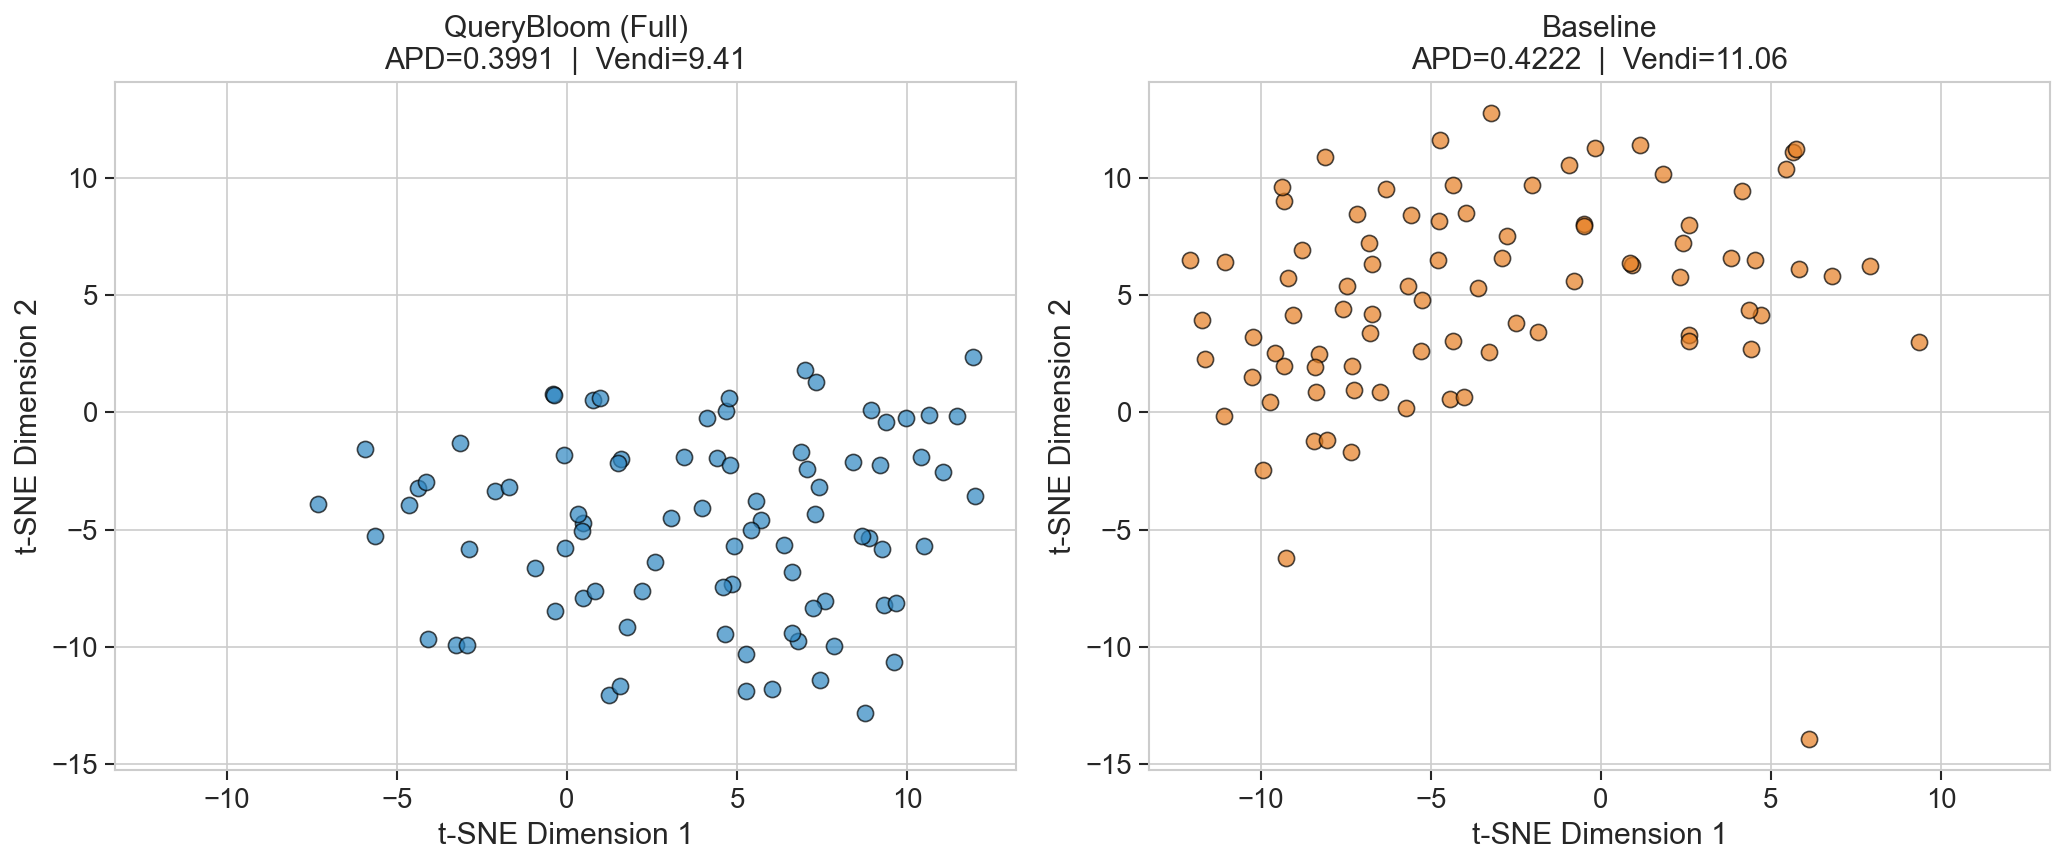

In [4]:
plot_semantic_embeddings(div1, div2, label1, label2, trim_outlier_pct=1)

## Figure 2 — Structural & Complexity Diversity

Three panels: (a) SPARQL feature distribution bars, (b) complexity-spread violins, (c) template / entity diversity scalars.

/Users/essamwisam/Desktop/UTA/Projects/NL2SparQL/misc/querybloom/analyze/plots/diversity_plots.py:535: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


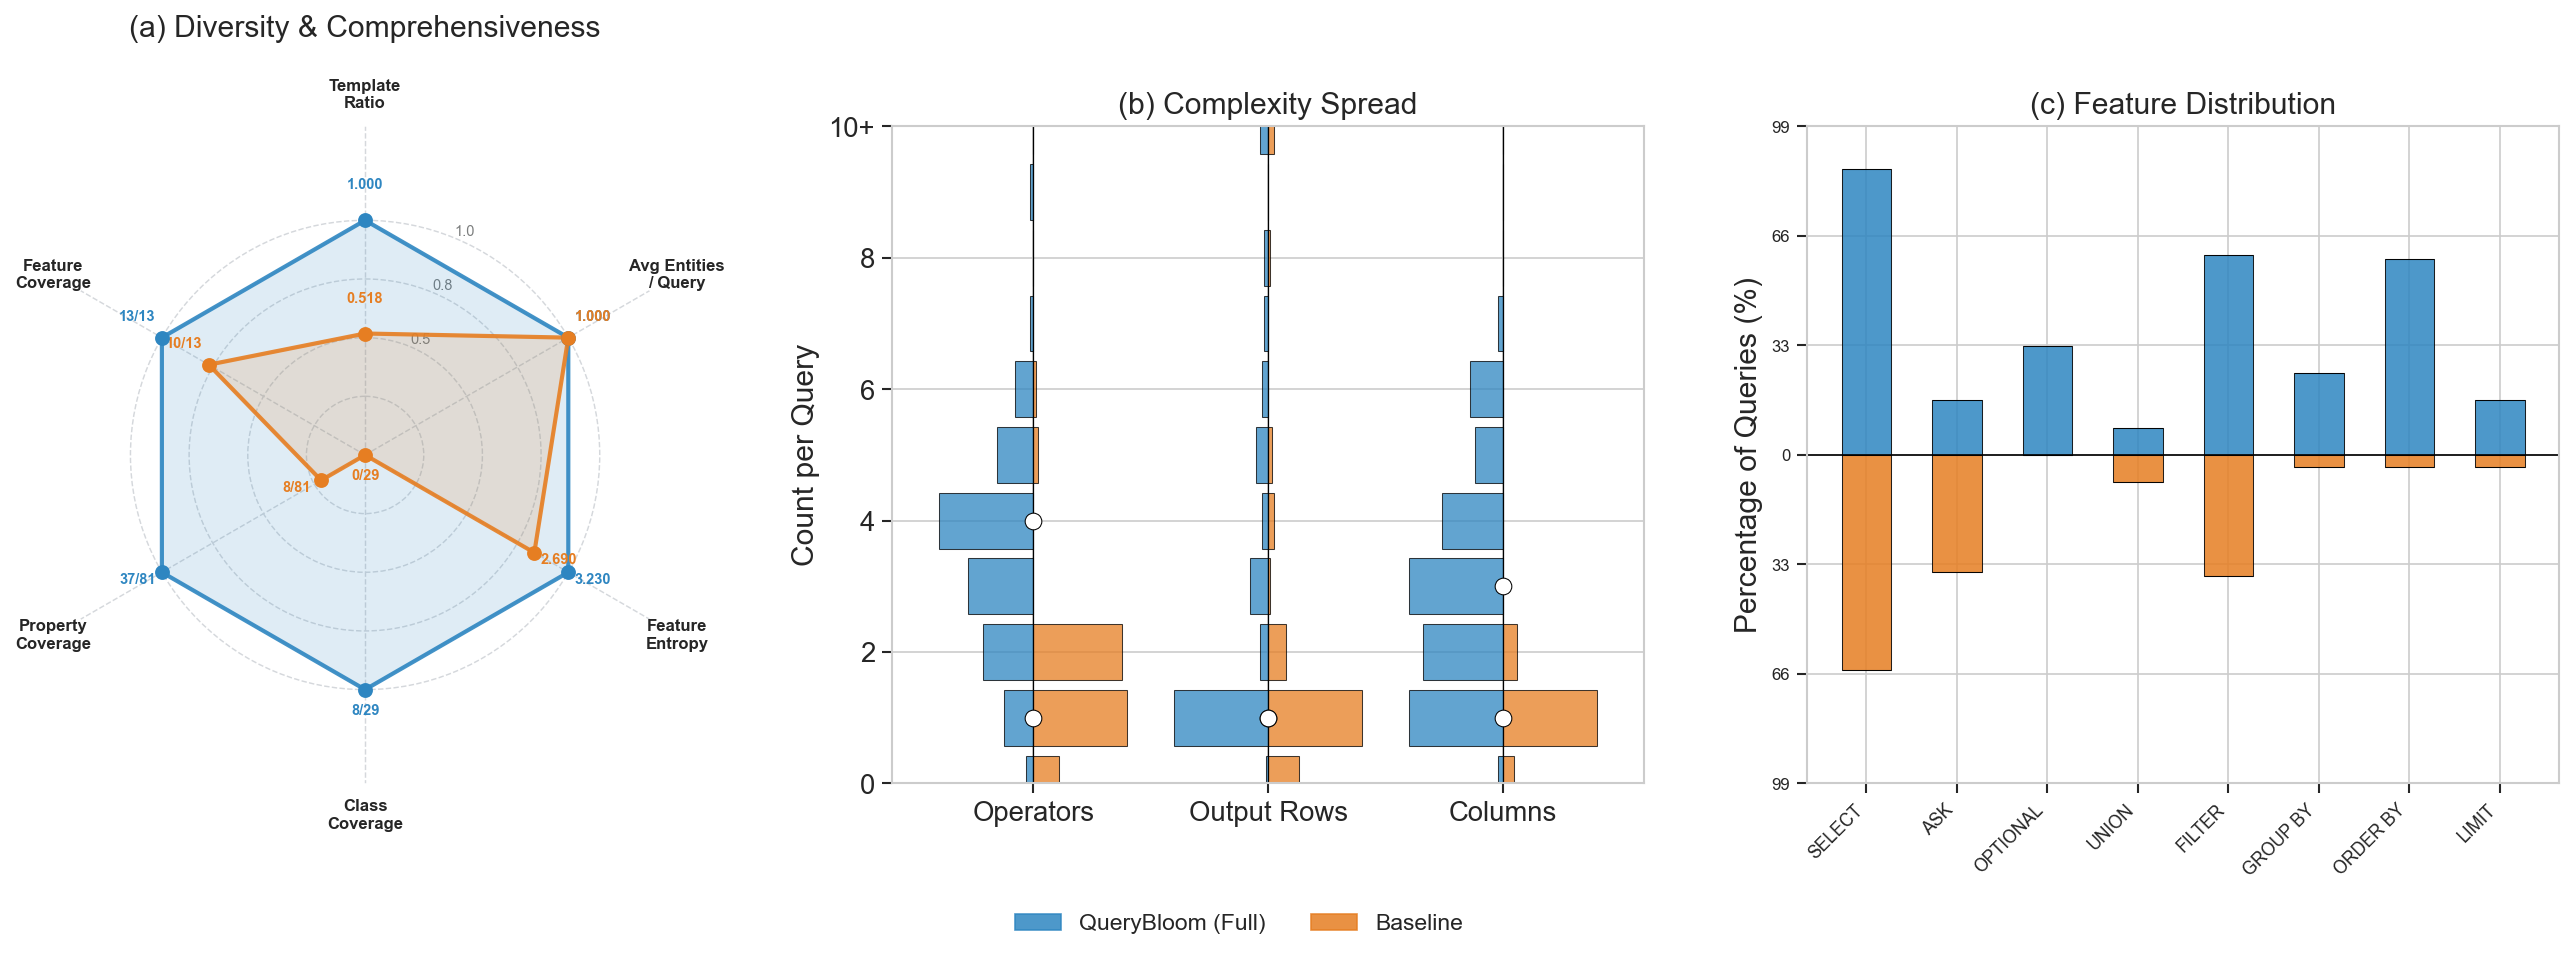

In [5]:
plot_structural_diversity(div1, div2, label1, label2, red1=red1, red2=red2, comp1=comp1, comp2=comp2, complexity_spread="histogram",show_redundancy_hatching=False)

## Figure 3 — Comprehensiveness Radar

3-spoke radar showing Class Coverage, Property Coverage, and Feature Coverage against the KG ontology.

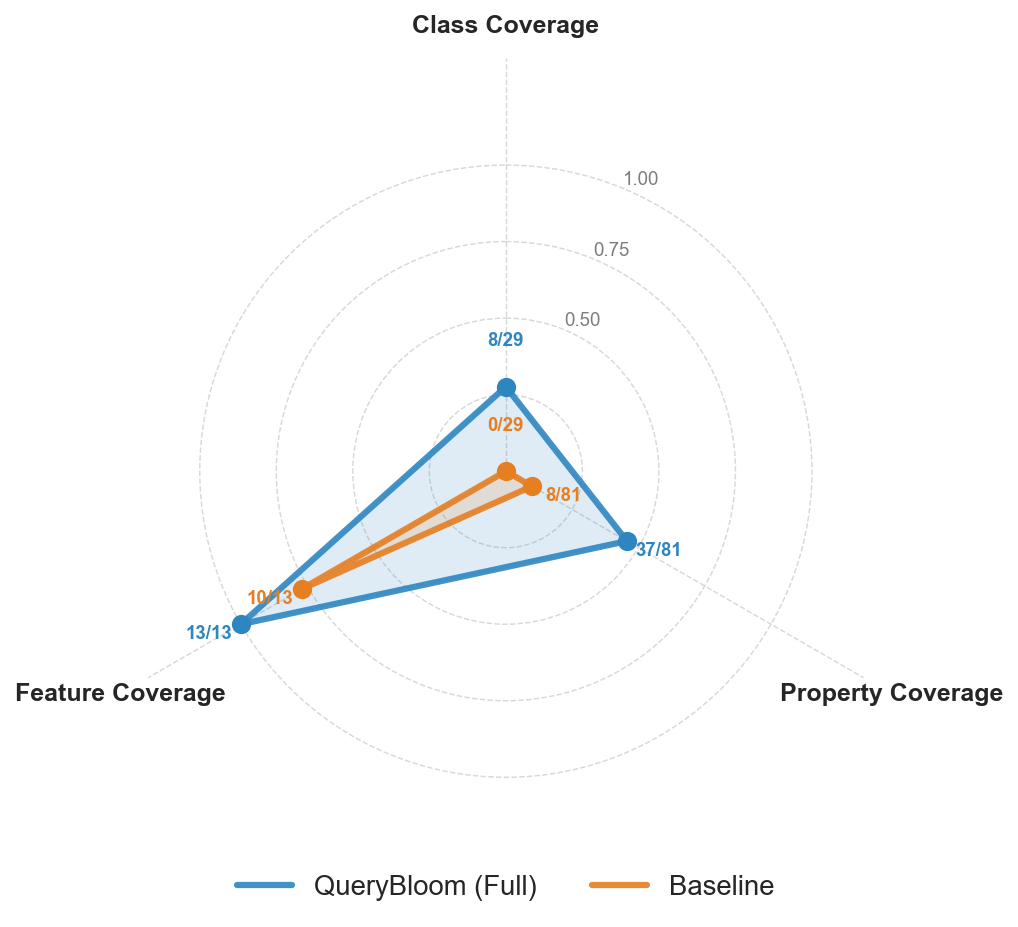

In [6]:
plot_comprehensiveness_radar(comp1, comp2, label1, label2)

## Figure 3b — Coverage Gaps Table

Random sample of classes and properties unique to one benchmark or missing from both.

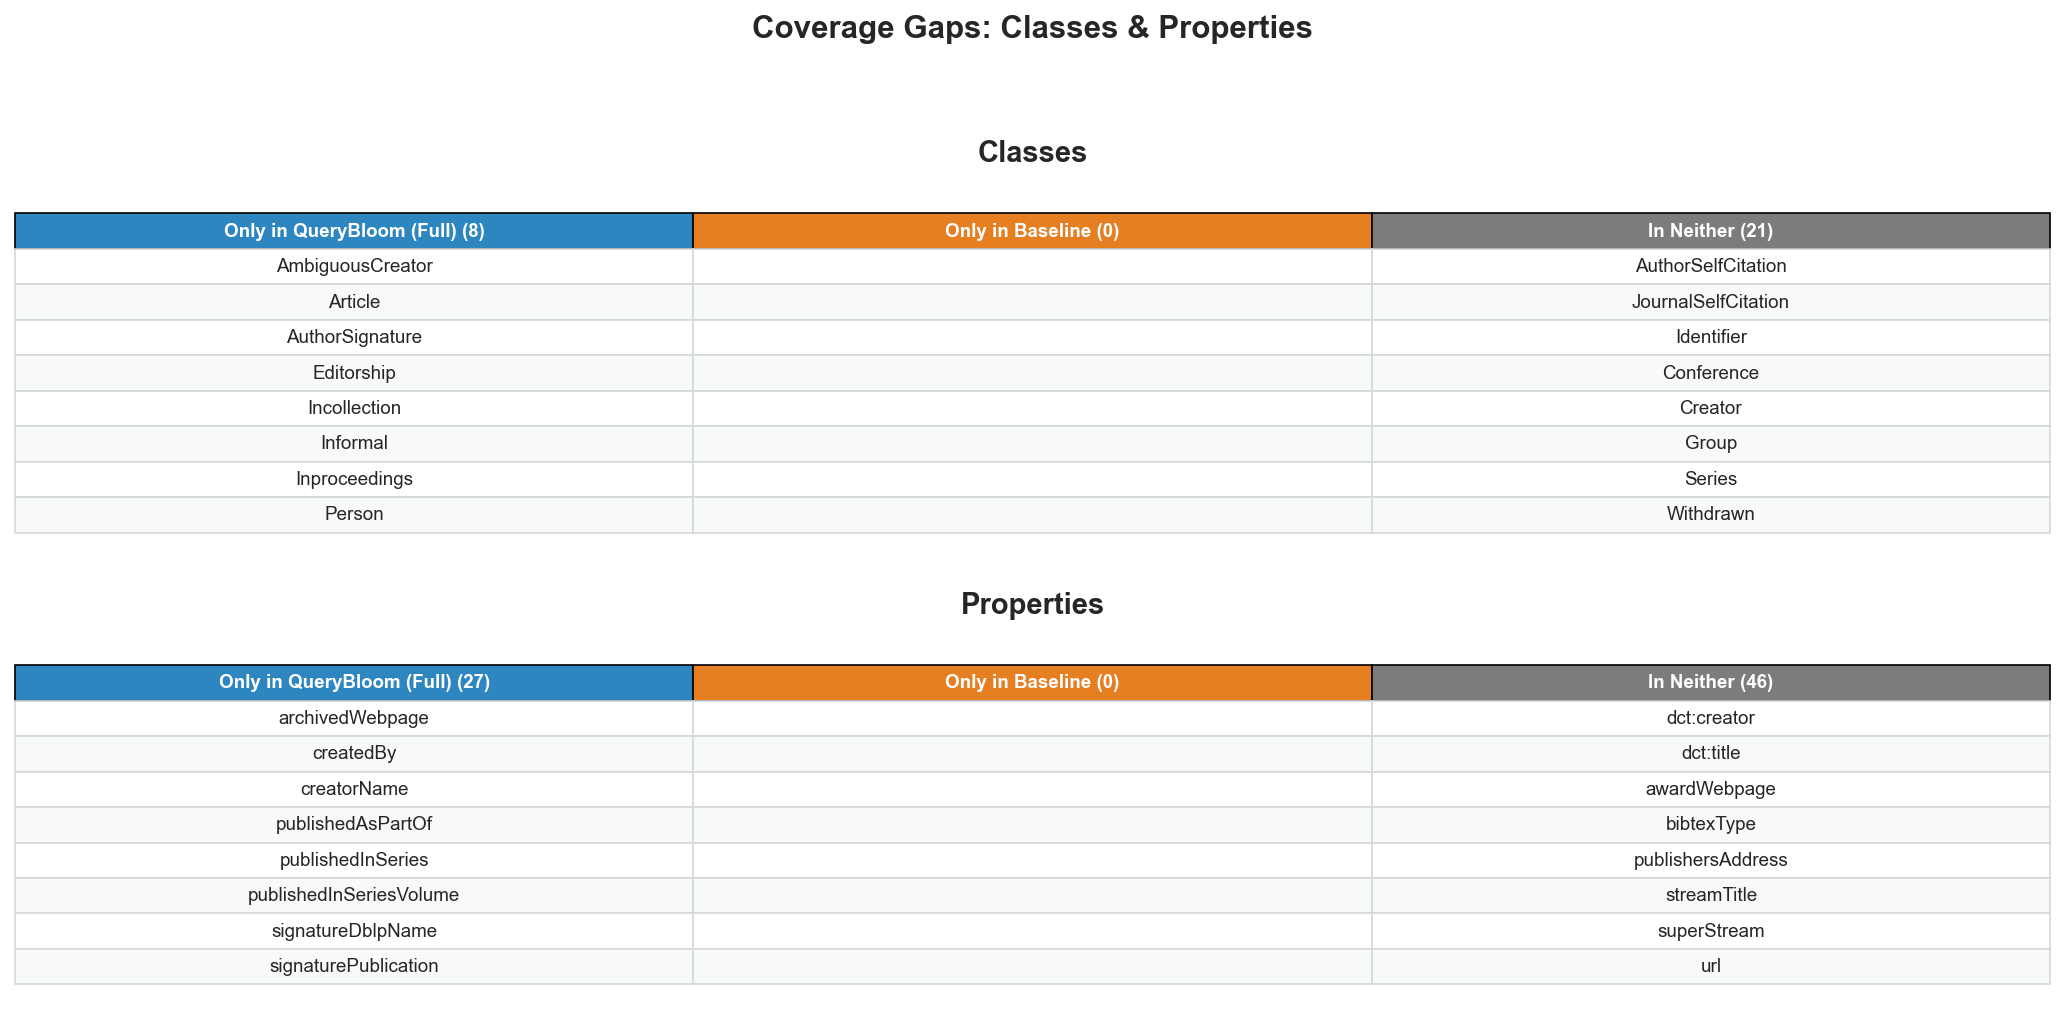

In [7]:
plot_coverage_table(queries1, queries2, kg_name, label1, label2, endpoint=endpoint)

In [8]:
from metrics.parsing import parse_and_extract_rdflib_metrics

# Look for rdf:type as a *property* in QueryBloom but not Baseline
target = "http://www.w3.org/1999/02/22-rdf-syntax-ns#type"

for label, queries in [(label1, queries1), (label2, queries2)]:
    count = 0
    for i, q in enumerate(queries):
        m = parse_and_extract_rdflib_metrics(q, endpoint=endpoint)
        if target in m["properties"]:
            count += 1
            if count <= 2:
                print(f"=== {label} query #{i} ===")
                print(q[:400])
                print("...\n")
    print(f"{label}: {count} queries have rdf:type as a property\n")

=== QueryBloom (Full) query #0 ===
PREFIX dblp: <https://dblp.org/rdf/schema#>
PREFIX person: <https://dblp.org/pid/74/>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>

SELECT DISTINCT ?paper ?title ?year ?venue ?pages ?authorCount
WHERE {
  ?paper a dblp:Inproceedings ;
         dblp:authoredBy person:6493 ;
         dblp:yearOfPublication ?year .
  FILTER (xsd:integer(STR(?year)) >= 2018)
  OPTIONAL { ?paper dblp:title ?title . 
...

=== QueryBloom (Full) query #1 ===
PREFIX dblp: <https://dblp.org/rdf/schema#>
PREFIX person: <https://dblp.org/pid/74/>

SELECT DISTINCT ?publication ?title ?year ?venue ?publisher ?series ?seriesVolume ?isbn
WHERE {
  {
    ?publication a dblp:Inproceedings ;
                 dblp:authoredBy person:6493 .
  }
  UNION
  {
    ?publication a dblp:Editorship ;
                 dblp:editedBy person:6493 .
  }
  OPTIONAL { ?publicatio
...

QueryBloom (Full): 71 queries have rdf:type as a property

Baseline: 0 queries have rdf:type as a property



In [9]:
from plots import plot_semantic_embeddings, plot_structural_diversity, plot_comprehensiveness_radar, plot_redundancy, plot_coverage_table, show_redundancy_examples


show_redundancy_examples(queries1, questions1, query_endpoint)

Detecting redundant queries …
  Running / loading 199 unique queries …


NL Question,SPARQL Query
"Which author of “Structuring Learning/Instructional Strategies through a State-based Modeling” also edited the proceedings in which it appeared? What are that author’s ORCID and affiliation, and how many conference papers in total did they author that appeared in proceedings they edited?","PREFIX dblp: <https://dblp.org/rdf/schema#> PREFIX aied: <https://dblp.org/rec/conf/aied/> SELECT DISTINCT ?author ?orcid ?affiliation ?selfEditedPaperCount WHERE { { SELECT ?author (COUNT(DISTINCT ?otherPaper) AS ?selfEditedPaperCount) WHERE { aied:HayashiBM09 a dblp:Inproceedings ; dblp:title ?title ; dblp:authoredBy ?author ; dblp:publishedAsPartOf ?targetProceedings . FILTER(STR(?title) = ""Structuring Learning/Instructional Strategies through a State-based Modeling."") ?targetProceedings a dblp:Editorship ; dblp:editedBy ?author . ?otherPaper a dblp:Inproceedings ; dblp:authoredBy ?author ; dblp:publishedAsPartOf ?otherProceedings . ?otherProceedings a dblp:Editorship ; dblp:editedBy ?author . } GROUP BY ?author } ?author a dblp:Person ; dblp:orcid ?orcid ; dblp:affiliation ?affiliation . }"
"When were the proceedings containing Makoto Amamiya’s paper “Agent-Community-Based P2P Semantic Web Information Retrieval System Architecture” published, what were their series volume, ISBN, and DOI, and who edited those proceedings?","PREFIX dblp: <https://dblp.org/rdf/schema#> PREFIX euc: <https://dblp.org/rec/conf/euc/> SELECT DISTINCT ?publicationYear ?seriesVolume ?isbn ?doi ?editor WHERE { euc:YuMA05 a dblp:Inproceedings ; dblp:title ?paperTitle ; dblp:authoredBy <https://dblp.org/pid/a/MakotoAmamiya> ; dblp:publishedAsPartOf ?proceedings . FILTER(STR(?paperTitle) = ""Agent-Community-Based P2P Semantic Web Information Retrieval System Architecture."") ?proceedings a dblp:Editorship ; dblp:yearOfPublication ?publicationYear ; dblp:publishedInSeriesVolume ?seriesVolume ; dblp:isbn ?isbn ; dblp:doi ?doi . euc:YuMA05 dblp:publishedAsPartOf/dblp:editedBy ?editor . }"
NL Question,SPARQL Query
"Which identified researchers coauthored “An In-Label Prioritizing Variable Branching Strategy of SAT Solvers for a Preferred Extension of Argumentation Frameworks.” alongside the unresolved author name “Jun Wu,” and what primary affiliation and primary homepage are available for each, if any? List the researchers alphabetically by name.","PREFIX dblp: <https://dblp.org/rdf/schema#> SELECT DISTINCT ?researcher ?researcherName ?primaryAffiliation ?primaryHomepage WHERE { ?paper a dblp:Inproceedings ; dblp:title ""An In-Label Prioritizing Variable Branching Strategy of SAT Solvers for a Preferred Extension of Argumentation Frameworks."" ; dblp:authoredBy ?ambiguousAuthor ; dblp:createdBy ?researcher . ?ambiguousAuthor a dblp:AmbiguousCreator ; dblp:creatorName ""Jun Wu"" . ?researcher a dblp:Person ; dblp:primaryCreatorName ?researcherName . OPTIONAL { ?researcher dblp:primaryAffiliation ?primaryAffiliation . } OPTIONAL { ?researcher dblp:primaryHomepage ?primaryHomepage . } } ORDER BY ?researcherName"
"For each conference paper coauthored by Min Zhang and Volker Stolz whose proceedings volume they both edited, what are the paper’s venue and primary access page, the proceedings series, volume number, publisher, and publication year, and, if available, its OpenCitations Meta identifier?","PREFIX dblp: <https://dblp.org/rdf/schema#> SELECT DISTINCT ?paperVenue ?proceedingsSeries ?publicationYear ?seriesVolume ?publisher ?paperPage ?openCitationsMetaId WHERE { ?minZhang dblp:primaryCreatorName ""Min Zhang"" . ?volkerStolz dblp:primaryCreatorName ""Volker Stolz"" . ?paper a dblp:Inproceedings ; dblp:authoredBy ?minZhang, ?volkerStolz ; dblp:publishedAsPartOf ?proceedings ; dblp:publishedIn ?paperVenue ; dblp:primaryDocumentPage ?paperPage . ?proceedings a dblp:Editorship ; dblp:editedBy ?minZhang, ?volkerStolz ; dblp:publishedIn ?proceedingsSeries ; dblp:yearOfPublication ?publicationYear ; dblp:publishedInSeriesVolume ?seriesVolume ; dblp:

Done.
